Lab 1
Biometria
Wojciech Hebisz

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

ZADANIA DO WYKONANIA 
1. Utwórz nowy notatnik Jupyter (lub skrypt Pythona). 
2. Zainstaluj i zaimportuj bibliotekę OpenCV. 
3. Wczytaj plik parrot.jpg: 
a. Wyświetl obraz w prawidłowych kolorach (przeprowadź konwersję przestrzeni kolorów BGR -> RGB). 
4. Wczytaj plik fingerprint.tif: 
a. Przekształć go do skali szarości i wyświetl obraz czarno-biały. 
b. Wykonaj adaptacyjne progowanie i wyświetl obraz binarny. 
c. Przetestuj wszystkie operacje morfologiczne na binarnym obrazie odcisku palca i wyświetl wyniki. 
d. Oczyść obraz odcisku palca z szumów, stosując kolejno otwarcie, a następnie zamknięcie. 
5. Wczytaj plik iris.bmp: 
a. Przekształć go do skali szarości i wyświetl obraz czarno-biały. 
b. Zastosuj detekcję krawędzi metodą Canny’ego i wyświetl wyniki. 
6. Prześlij notatnik (lub plik Pythona) do odpowiedniego folderu w Teams (lab_data bieżąca) ze swoim numerem 
indeksu w nazwie pliku.

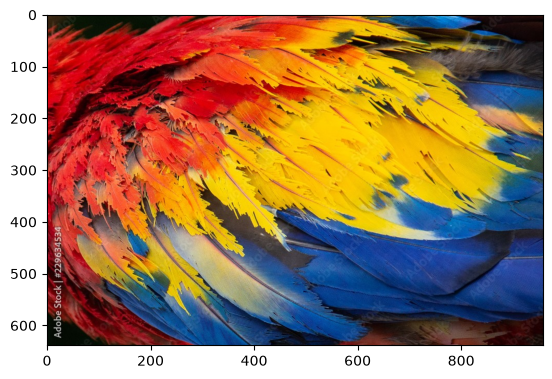

In [2]:
# 1. Wczytanie pliku z dysku
sciezka = "parrot.jpg"
img = cv2.imread(sciezka)

# 2. Sprawdzenie, czy plik na pewno został wczytany
# Jeśli ścieżka jest błędna, OpenCV NIE wyrzuca błędu, tylko zwraca None!
if img is None:
    raise FileNotFoundError(f"Nie znaleziono pliku pod ścieżką: {sciezka}")

# 3. Konwersja z BGR do RGB (niezbędna do poprawnego wyświetlenia kolorów)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# . Wyświetlenie w notatniku
plt.imshow(img_rgb)
#plt.axis('off')  # ukrycie osi z pikselami
plt.show()

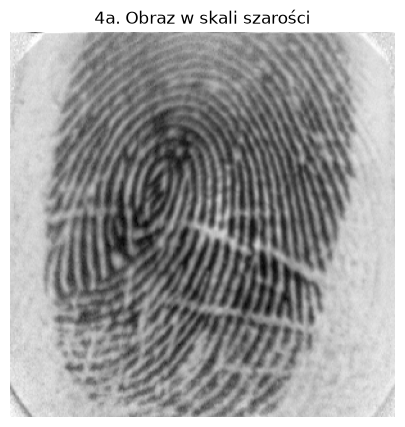

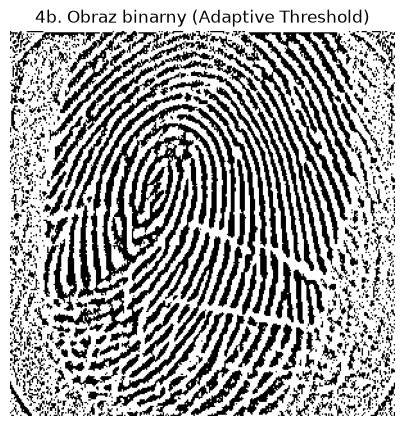

In [3]:
# 4. Wczytanie pliku fingerprint.tif
# Flaga IMREAD_GRAYSCALE wczytuje obraz bezpośrednio jako 1-kanałowy (skala szarości)
img_gray = cv2.imread("fingerprint.tif", cv2.IMREAD_GRAYSCALE)

# a. Wyświetlenie obrazu w skali szarości
plt.figure(figsize=(5, 5))
plt.imshow(img_gray, cmap="gray")
plt.title("4a. Obraz w skali szarości")
plt.axis("off")
plt.show()

# b. Adaptacyjne progowanie i wyświetlenie obrazu binarnego
# Parametry: max_value=255, metoda gaussa, THRESH_BINARY, rozmiar_bloku=11, stała_C=2
img_binary = cv2.adaptiveThreshold(
    img_gray, 
    255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY, 
    11, 
    2
)

plt.figure(figsize=(5, 5))
plt.imshow(img_binary, cmap="gray")
plt.title("4b. Obraz binarny (Adaptive Threshold)")
plt.axis("off")
plt.show()

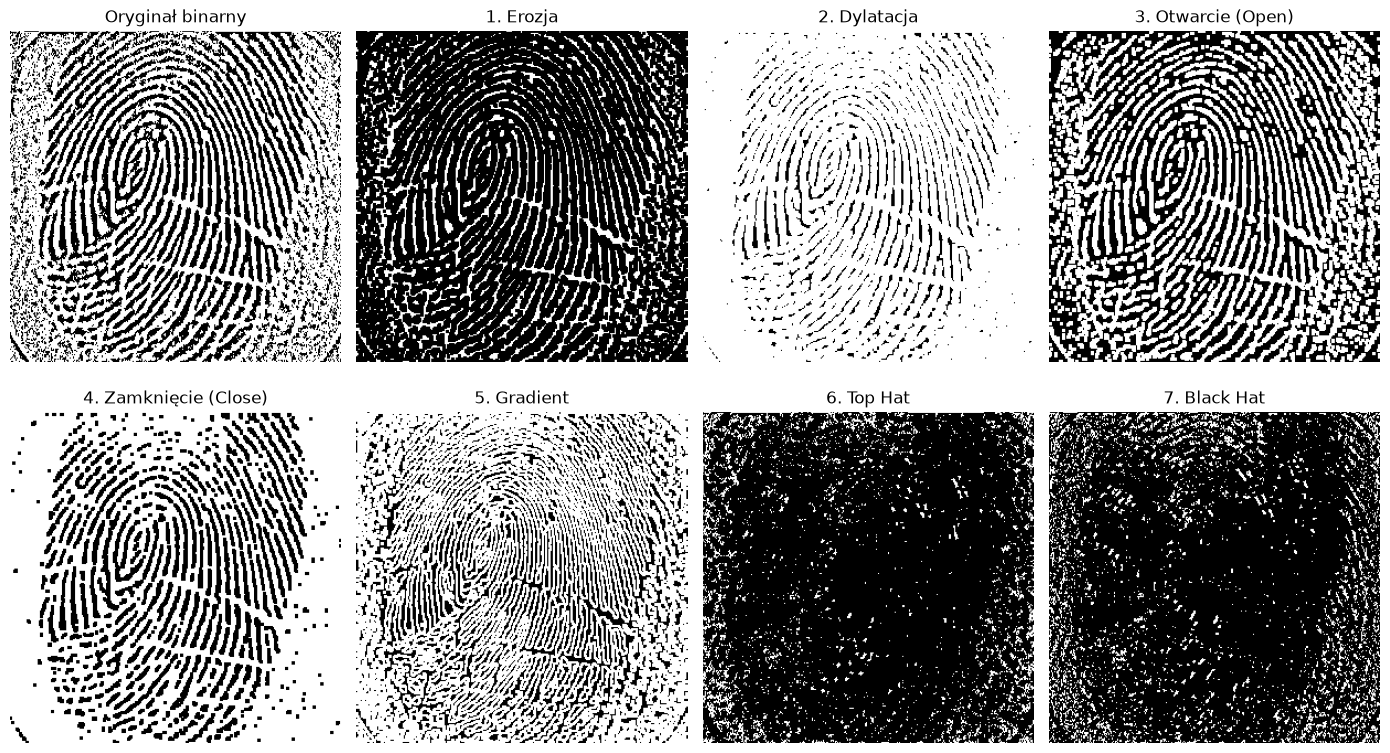

In [4]:
# Element strukturujący (kernel) - standardowy kwadrat 3x3 lub 5x5
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Obliczenie wszystkich operacji
operations = {
    "1. Erozja": cv2.erode(img_binary, kernel, iterations=1),
    "2. Dylatacja": cv2.dilate(img_binary, kernel, iterations=1),
    "3. Otwarcie (Open)": cv2.morphologyEx(img_binary, cv2.MORPH_OPEN, kernel),
    "4. Zamknięcie (Close)": cv2.morphologyEx(img_binary, cv2.MORPH_CLOSE, kernel),
    "5. Gradient": cv2.morphologyEx(img_binary, cv2.MORPH_GRADIENT, kernel),
    "6. Top Hat": cv2.morphologyEx(img_binary, cv2.MORPH_TOPHAT, kernel),
    "7. Black Hat": cv2.morphologyEx(img_binary, cv2.MORPH_BLACKHAT, kernel),
}

# Wyświetlenie wszystkich wyników w siatce
plt.figure(figsize=(14, 8))

# Obraz bazowy
plt.subplot(2, 4, 1)
plt.imshow(img_binary, cmap="gray")
plt.title("Oryginał binarny")
plt.axis("off")

# Wygenerowane operacje
for i, (nazwa, wynik) in enumerate(operations.items(), start=2):
    plt.subplot(2, 4, i)
    plt.imshow(wynik, cmap="gray")
    plt.title(nazwa)
    plt.axis("off")

plt.tight_layout()
plt.show()

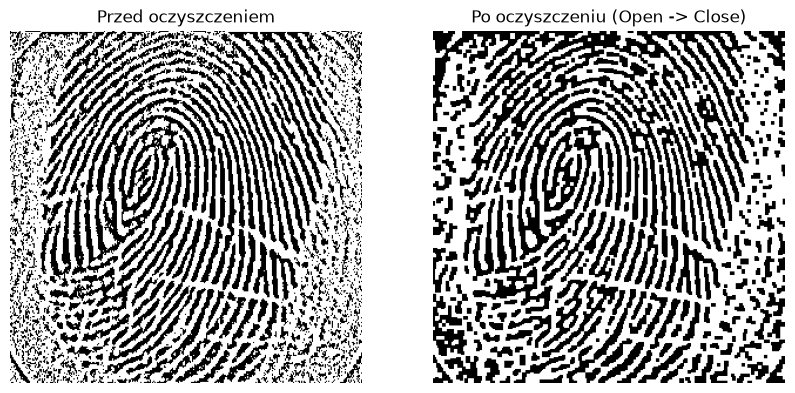

In [5]:
# Używamy małego jądra (3x3), aby nie zlać ze sobą delikatnych linii papilarnych
kernel_clean = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Krok 1: Otwarcie (usunięcie drobnych białych kropek w tle)
opened = cv2.morphologyEx(img_binary, cv2.MORPH_OPEN, kernel_clean)

# Krok 2: Zamknięcie (połączenie przerwanych linii i wypełnienie czarnych ubytków)
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel_clean)

# Porównanie przed i po oczyszczeniu
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_binary, cmap="gray")
plt.title("Przed oczyszczeniem")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cleaned, cmap="gray")
plt.title("Po oczyszczeniu (Open -> Close)")
plt.axis("off")

plt.show()

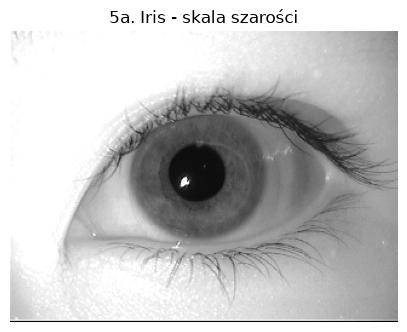

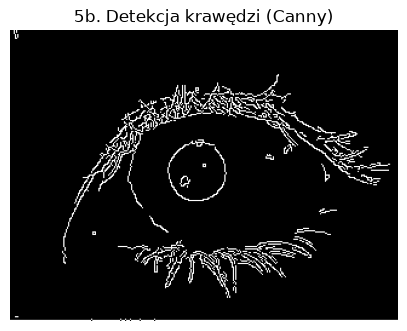

In [6]:
# 5. Wczytanie pliku iris.bmp i (a) przekształcenie do skali szarości 
# Flaga cv2.IMREAD_GRAYSCALE od razu wczytuje obraz w skali szarości
iris_gray = cv2.imread("iris.bmp", cv2.IMREAD_GRAYSCALE)

# Wyświetlenie obrazu w skali szarości
plt.figure(figsize=(5, 5))
plt.imshow(iris_gray, cmap="gray")
plt.title("5a. Iris - skala szarości")
plt.axis("off")
plt.show()

# b. Detekcja krawędzi metodą Canny'ego 
# Dwa progi histerezy: dolny (threshold1) i górny (threshold2)
edges = cv2.Canny(iris_gray, threshold1=100, threshold2=200)

# Wyświetlenie wyników detekcji krawędzi
plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap="gray")
plt.title("5b. Detekcja krawędzi (Canny)")
plt.axis("off")
plt.show()